<a href="https://colab.research.google.com/github/ryhanhkwshky821-cpu/Untitled18.ipynb/blob/main/Copy_of_Untitled10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q tensorflow huggingface_hub scikit-learn seaborn pandas

In [ ]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")
print("TensorFlow version:", tf.version)

All libraries imported successfully!
TensorFlow version: <module 'tensorflow._api.v2.version' from '/usr/local/lib/python3.13/dist-packages/tensorflow/_api/v2/version/__init__.py'>


In [ ]:
from huggingface_hub import snapshot_download

dataset_path = snapshot_download(
    repo_id="AIOmarRehan/Cats_and_Dogs",
    repo_type="dataset"
)

print("دیتاست دوباره آماده شد!")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

دیتاست دوباره آماده شد!


In [ ]:
for root, dirs, files in os.walk(dataset_path):
    print(root, ":", len(files), "files")

/root/.cache/huggingface/hub/datasets--AIOmarRehan--Cats_and_Dogs/snapshots/7f39a3519ae23d0ede13bb9ef91a87e93daac320 : 2 files
/root/.cache/huggingface/hub/datasets--AIOmarRehan--Cats_and_Dogs/snapshots/7f39a3519ae23d0ede13bb9ef91a87e93daac320/data : 2 files


In [ ]:
image_paths = []
labels = []

for ext in ['jpg', 'jpeg', 'png']:
    image_paths += glob.glob(
        dataset_path + '/**/*.' + ext,
        recursive=True
    )

valid_data = []

for path in image_paths:

    folder = os.path.basename(
        os.path.dirname(path)
    ).lower()

    filename = os.path.basename(path).lower()

    if folder in ['cat', 'cats'] or filename.startswith('cat.'):
        valid_data.append((path, 0))

    elif folder in ['dog', 'dogs'] or filename.startswith('dog.'):
        valid_data.append((path, 1))

image_paths = [x[0] for x in valid_data]
labels = [x[1] for x in valid_data]

print("Total images:", len(image_paths))
print("Cats:", labels.count(0))
print("Dogs:", labels.count(1))

Total images: 0
Cats: 0
Dogs: 0


In [ ]:
import pandas as pd
import glob
import os

parquet_files = glob.glob(
    dataset_path + '/**/*.parquet',
    recursive=True
)

print("Parquet files:", parquet_files)

df = pd.concat(
    [pd.read_parquet(file) for file in parquet_files],
    ignore_index=True
)

print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nFirst rows:")
display(df.head())

Parquet files: ['/root/.cache/huggingface/hub/datasets--AIOmarRehan--Cats_and_Dogs/snapshots/7f39a3519ae23d0ede13bb9ef91a87e93daac320/data/train-00001-of-00002.parquet', '/root/.cache/huggingface/hub/datasets--AIOmarRehan--Cats_and_Dogs/snapshots/7f39a3519ae23d0ede13bb9ef91a87e93daac320/data/train-00000-of-00002.parquet']
Dataset shape: (24998, 2)

Columns:
Index(['image', 'label'], dtype='object')

First rows:


,image,label
0,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,1
1,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,1
2,{'bytes': b'\xff\xd8\xff\xe15\xbaExif\x00\x00I...,1
3,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,1
4,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,1


In [ ]:
import os

print("Dataset path:", dataset_path)

for root, dirs, files in os.walk(dataset_path):
    print("\nFolder:", root)
    print("Subfolders:", dirs[:10])
    print("Files:", files[:10])

Dataset path: /root/.cache/huggingface/hub/datasets--AIOmarRehan--Cats_and_Dogs/snapshots/7f39a3519ae23d0ede13bb9ef91a87e93daac320

Folder: /root/.cache/huggingface/hub/datasets--AIOmarRehan--Cats_and_Dogs/snapshots/7f39a3519ae23d0ede13bb9ef91a87e93daac320
Subfolders: ['data']
Files: ['.gitattributes', 'README.md']

Folder: /root/.cache/huggingface/hub/datasets--AIOmarRehan--Cats_and_Dogs/snapshots/7f39a3519ae23d0ede13bb9ef91a87e93daac320/data
Subfolders: []
Files: ['train-00001-of-00002.parquet', 'train-00000-of-00002.parquet']


In [ ]:
all_files = []

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        all_files.append(os.path.join(root, file))

print("Total files:", len(all_files))
print("Sample files:")

for file in all_files[:20]:
    print(file)

Total files: 4
Sample files:
/root/.cache/huggingface/hub/datasets--AIOmarRehan--Cats_and_Dogs/snapshots/7f39a3519ae23d0ede13bb9ef91a87e93daac320/.gitattributes
/root/.cache/huggingface/hub/datasets--AIOmarRehan--Cats_and_Dogs/snapshots/7f39a3519ae23d0ede13bb9ef91a87e93daac320/README.md
/root/.cache/huggingface/hub/datasets--AIOmarRehan--Cats_and_Dogs/snapshots/7f39a3519ae23d0ede13bb9ef91a87e93daac320/data/train-00001-of-00002.parquet
/root/.cache/huggingface/hub/datasets--AIOmarRehan--Cats_and_Dogs/snapshots/7f39a3519ae23d0ede13bb9ef91a87e93daac320/data/train-00000-of-00002.parquet


In [ ]:
all_files = []

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        all_files.append(os.path.join(root, file))

print("Total files:", len(all_files))
print("Sample files:")

for file in all_files[:20]:
    print(file)

Total files: 4
Sample files:
/root/.cache/huggingface/hub/datasets--AIOmarRehan--Cats_and_Dogs/snapshots/7f39a3519ae23d0ede13bb9ef91a87e93daac320/.gitattributes
/root/.cache/huggingface/hub/datasets--AIOmarRehan--Cats_and_Dogs/snapshots/7f39a3519ae23d0ede13bb9ef91a87e93daac320/README.md
/root/.cache/huggingface/hub/datasets--AIOmarRehan--Cats_and_Dogs/snapshots/7f39a3519ae23d0ede13bb9ef91a87e93daac320/data/train-00001-of-00002.parquet
/root/.cache/huggingface/hub/datasets--AIOmarRehan--Cats_and_Dogs/snapshots/7f39a3519ae23d0ede13bb9ef91a87e93daac320/data/train-00000-of-00002.parquet


In [ ]:
print("Columns:", df.columns.tolist())

print("\nDataset information:")
print(df.info())

print("\nFirst sample:")
display(df.iloc[0])

Columns: ['image', 'label']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24998 entries, 0 to 24997
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   image   24998 non-null  object
 1   label   24998 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 390.7+ KB
None

First sample:


,0
image,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...
label,1


In [ ]:
from io import BytesIO

image_data = df['image'].apply(lambda x: x['bytes']).tolist()

labels = df['label'].astype(int).tolist()

print("Total images:", len(image_data))
print("Label counts:")
print(df['label'].value_counts())

Total images: 24998
Label counts:
label
1    12499
0    12499
Name: count, dtype: int64


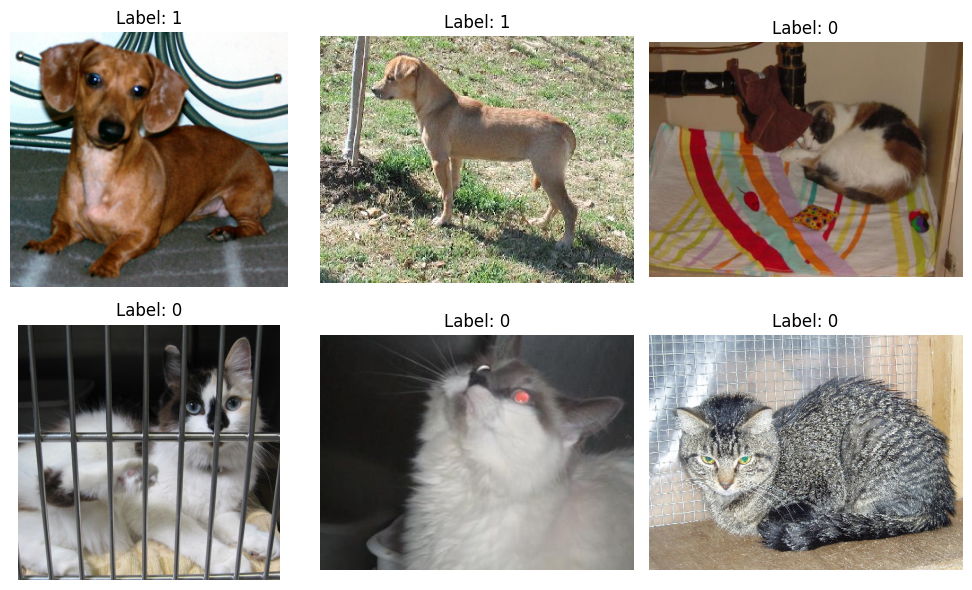

In [ ]:
import random
from PIL import Image
from io import BytesIO

plt.figure(figsize=(10, 6))

for i in range(6):

    index = random.randint(0, len(image_data) - 1)

    img = Image.open(
        BytesIO(image_data[index])
    ).convert('RGB')

    plt.subplot(2, 3, i + 1)

    plt.imshow(img)

    plt.title("Label: " + str(labels[index]))

    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import glob

parquet_files = glob.glob(
    dataset_path + '/**/*.parquet',
    recursive=True
)

df = pd.concat(
    [pd.read_parquet(file) for file in parquet_files],
    ignore_index=True
)

print("Dataset shape:", df.shape)
print("\nLabel counts:")
print(df.groupby('label').size())

Dataset shape: (24998, 2)

Label counts:
label
0    12499
1    12499
dtype: int64


In [ ]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

In [ ]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.MeanSquaredError(name='mse')
    ]
)

In [ ]:
from PIL import Image
from io import BytesIO
import numpy as np
import tensorflow as tf

IMG_SIZE = 128
BATCH_SIZE = 32

def make_dataset(images, labels, training=False):
    def generator():
        for img_bytes, label in zip(images, labels):
            try:
                img = Image.open(BytesIO(img_bytes))
                img = img.convert("RGB")
                img = img.resize((IMG_SIZE, IMG_SIZE))
                img = np.array(img, dtype=np.float32) / 255.0
                yield img, np.float32(label)
            except:
                continue

    ds = tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            tf.TensorSpec((128, 128, 3), tf.float32),
            tf.TensorSpec((), tf.float32)
        )
    )

    if training:
        ds = ds.shuffle(500)

    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [ ]:
from sklearn.model_selection import train_test_split

image_data = df['image'].apply(lambda x: x['bytes']).tolist()
labels = df['label'].astype(int).tolist()

X_train, X_temp, y_train, y_temp = train_test_split(
    image_data, labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Data is ready!")

Data is ready!


In [ ]:
train_ds = make_dataset(X_train[:1000], y_train[:1000], True)

val_ds = make_dataset(X_val[:200], y_val[:200])

print("Datasets are ready!")

Datasets are ready!


In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3
)

Epoch 1/3
     32/Unknown 40s 1s/step - accuracy: 0.5170 - loss: 0.8992 - mse: 0.2879

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


32/32 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.5160 - loss: 0.7709 - mse: 0.2658 - val_accuracy: 0.5450 - val_loss: 0.6894 - val_mse: 0.2481
Epoch 2/3
32/32 ━━━━━━━━━━━━━━━━━━━━ 74s 970ms/step - accuracy: 0.5920 - loss: 0.6732 - mse: 0.2403 - val_accuracy: 0.5200 - val_loss: 0.6925 - val_mse: 0.2492
Epoch 3/3
32/32 ━━━━━━━━━━━━━━━━━━━━ 34s 975ms/step - accuracy: 0.6610 - loss: 0.6194 - mse: 0.2155 - val_accuracy: 0.5700 - val_loss: 0.7612 - val_mse: 0.2764


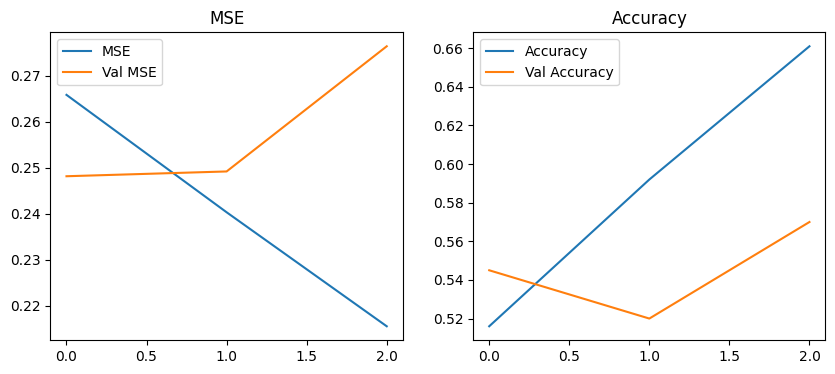

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['mse'], label='MSE')
plt.plot(history.history['val_mse'], label='Val MSE')
plt.title('MSE')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy')
plt.legend()

plt.show()

In [ ]:
test_ds = make_dataset(X_test[:200], y_test[:200])

print("Test data is ready!")

Test data is ready!


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend((predictions.ravel() > 0.5).astype(int))

print("Accuracy:", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred, zero_division=0))
print("Recall:", recall_score(y_true, y_pred, zero_division=0))
print("F1-score:", f1_score(y_true, y_pred, zero_division=0))

Accuracy: 0.53
Precision: 1.0
Recall: 0.050505050505050504
F1-score: 0.09615384615384616


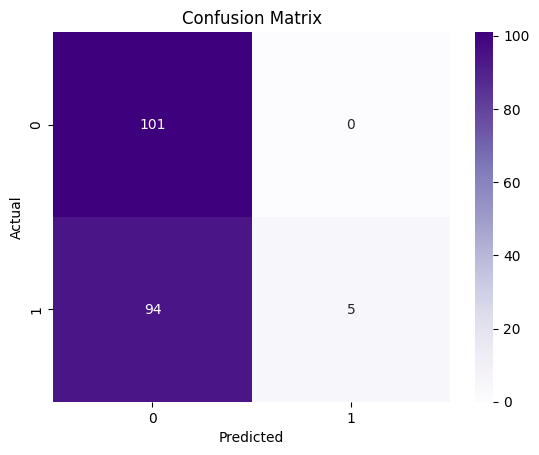

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Purples')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
from tensorflow.keras import layers, models

simple_model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

simple_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

simple_history = simple_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3
)

Epoch 1/3
     32/Unknown 22s 573ms/step - accuracy: 0.4865 - loss: 1.6808

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


32/32 ━━━━━━━━━━━━━━━━━━━━ 25s 658ms/step - accuracy: 0.5130 - loss: 1.1535 - val_accuracy: 0.4600 - val_loss: 0.7575
Epoch 2/3
32/32 ━━━━━━━━━━━━━━━━━━━━ 21s 589ms/step - accuracy: 0.6120 - loss: 0.6508 - val_accuracy: 0.5950 - val_loss: 0.6789
Epoch 3/3
32/32 ━━━━━━━━━━━━━━━━━━━━ 42s 618ms/step - accuracy: 0.6930 - loss: 0.5754 - val_accuracy: 0.5850 - val_loss: 0.6946


In [ ]:
print("مدل دو لایه:")
print("Accuracy:", max(history.history['val_accuracy']))

print("مدل یک لایه:")
print("Accuracy:", max(simple_history.history['val_accuracy']))

مدل دو لایه:
Accuracy: 0.5699999928474426
مدل یک لایه:
Accuracy: 0.5950000286102295


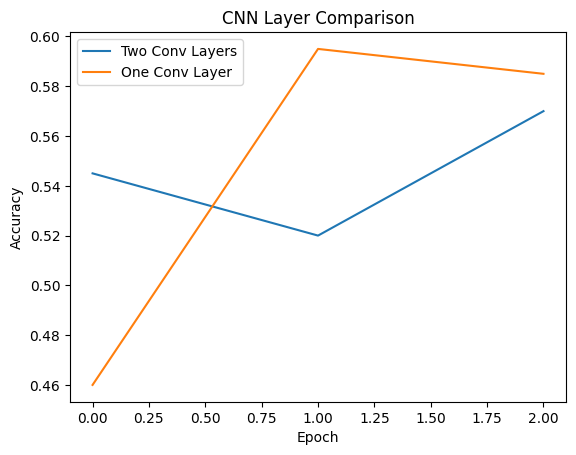

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['val_accuracy'], label='Two Conv Layers')
plt.plot(simple_history.history['val_accuracy'], label='One Conv Layer')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('CNN Layer Comparison')
plt.legend()
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=['Cat', 'Dog'],
    zero_division=0
))

              precision    recall  f1-score   support

         Cat       0.52      1.00      0.68       101
         Dog       1.00      0.05      0.10        99

    accuracy                           0.53       200
   macro avg       0.76      0.53      0.39       200
weighted avg       0.76      0.53      0.39       200



In [ ]:
print("Accuracy:", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred, zero_division=0))
print("Recall:", recall_score(y_true, y_pred, zero_division=0))
print("F1-score:", f1_score(y_true, y_pred, zero_division=0))

Accuracy: 0.53
Precision: 1.0
Recall: 0.050505050505050504
F1-score: 0.09615384615384616


In [ ]:
print("Two-layer CNN:", max(history.history['val_accuracy']))
print("One-layer CNN:", max(simple_history.history['val_accuracy']))

Two-layer CNN: 0.5699999928474426
One-layer CNN: 0.5950000286102295


In [ ]:
model.save("cat_dog_cnn.keras")
print("Model saved successfully!")

Model saved successfully!


In [ ]:
plt.savefig("comparison.png")

<Figure size 640x480 with 0 Axes>

In [ ]:
plt.savefig("mse.png")

<Figure size 640x480 with 0 Axes>